# Will there be a bike? Progress report, model part

**Team 3, MIE1517.** For every Toronto Bike Share station we forecast the probability that at least one
classic bike, and at least one e-bike, will be docked there h = 2–15 minutes from now.

**Summary.**
<span style="color:#1f5fbf">[D1] Our best model so far is the MLP 2×256, dropout 0.3 network. On the validation days it beats an honest 'what you see now' forecast (calibrated persistence) by a Brier skill score of 0.154 for classic bikes and 0.117 for e-bikes, and plain persistence by 0.205 / 0.174.</span>
<span style="color:#1f5fbf">[D2] On the held-out test days (read once) the skill against calibrated persistence is 0.125 / 0.092.</span>
<span style="color:#1f5fbf">[D3] What is left: a second, larger dataset (data v2), longer history for the sequence models, and a rider-level evaluation; the plan and dates are in Section 8.</span>

This notebook reads cached results; every number is printed from a table written by a script in `src/`.
Blue text marked [Dn] is a draft; red text marked [Cn] is a claim still to be checked.

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
T, F = ROOT / "reports" / "tables", ROOT / "reports" / "figures"
pd.set_option("display.width", 100)
pd.set_option("display.precision", 3)

RERUN = False  # True: rerun the val scripts (about 1 h); the test score is never rerun
if RERUN:
    py = sys.executable
    for args in [["test_score_prob.py"],
                 ["46_prob_search.py", "--logreg", "--lgbm"],
                 ["46_prob_search.py", "--run", "mlp_2x64_e8", "mlp_2x256_do0.1",
                  "mlp_2x256_do0.3", "gru64_3x256_do0.1"],
                 ["47_prob_report.py"]]:
        subprocess.run([py, *args], cwd=ROOT / "src", check=True)

## 1. Data collected

<span style="color:#1f5fbf">[D4] We poll the public Toronto Bike Share feed (GBFS) every minute since Sep 29, with backup pollers, and add Environment Canada weather. The team table (data-v1) turns the polls into one row per station, anchor time t (every 10 min) and horizon h, with the counts now and 10 and 30 min before, the station, the time of day and the weather as inputs. Only anchors where some count is 2 or less are kept: those are the cases where a rider may find no bike.</span>
<span style="color:#c00000">[C1] Pollers and weather source as described; anchor rule from the table's documentation.</span>

The table below gives the size of each split and how often the answer changes: the *flip rate* is the share of
rows whose 'at least one bike' status differs between t and t + h.
<span style="color:#1f5fbf">[D5] Status flips are rare: 2.6 % of val rows for classic bikes and 4.3 % for e-bikes, so 'what you see now' is already a strong forecast.</span>

In [2]:
data = pd.read_csv(T / "prob_data.csv")
if (T / "prob_test_data.csv").exists():
    data = pd.concat([data, pd.read_csv(T / "prob_test_data.csv")])
show = data[["split", "rows", "stations", "first_day", "last_day",
             "classic_base_rate", "ebike_base_rate",
             "classic_flip_rate", "ebike_flip_rate"]]
show.columns = ["split", "rows", "stations", "from", "to",
                "P(>=1 classic)", "P(>=1 e-bike)",
                "flip classic", "flip e-bike"]
show.set_index("split")

,rows,stations,from,to,P(>=1 classic),P(>=1 e-bike),flip classic,flip e-bike
split,,,,,,,,
train,7525845,1071,2026-09-29,2026-10-18,0.738,0.380,0.024,0.040
val,2083617,1071,2026-10-19,2026-10-23,0.717,0.363,0.026,0.043
test,1747660,1072,2026-10-24,2026-10-28,0.723,0.379,0.022,0.037


## 2. Task and score

**Output.** For each bike type, p = P(at least one bike at t + h), h = 2–15 min. One model covers all stations
and horizons (h is an input). Loss: binary cross-entropy.
<span style="color:#1f5fbf">[D6] We moved from forecasting the count (with MSE) to this probability because a rider's question is 'will there be a bike?', and a probability says how sure the answer is.</span>

**Score.** The Brier score, mean (p − y)², and the Brier skill score against a reference,
BSS = 1 − Brier_model / Brier_ref (0 = no better than the reference, 1 = perfect).
<span style="color:#1f5fbf">[D7] We do not use log loss against persistence: persistence says 0 or 1, so every miss costs log(0) = infinity. The Brier score is finite for 0/1 forecasts and is still a proper score.</span>

Three references, all fitted on the training days only (`src/score_prob.py`, checked on toy cases in
`src/test_score_prob.py`):

| Reference | Forecast |
|---|---|
| Persistence | 1 if a bike is there now, else 0 |
| Calibrated persistence | P(bike at t + h given the count now and h), from the training days |
| Climatology | the station's rate at that hour of the week, from the training days |

<span style="color:#1f5fbf">[D8] Calibrated persistence is the bar that matters: it already knows that '1 bike now' does not mean a sure bike later, and it beats raw persistence by 0.061 / 0.065 (classic / e-bike, val). Climatology ignores the count now and is far weaker (BSS against persistence -4.51 / -3.93).</span>

In [3]:
r = subprocess.run([sys.executable, "test_score_prob.py"], cwd=ROOT / "src",
                   capture_output=True, text=True)
lines = r.stdout.splitlines()
print(f"{sum(l.startswith('ok') for l in lines)} toy checks ok, "
      f"{sum(l.startswith('FAIL') for l in lines)} failed")

25 toy checks ok, 0 failed


## 3. Model

<span style="color:#1f5fbf">[D9] The chosen network (MLP 2×256, dropout 0.3) takes the 20 inputs of the table (horizon h; classic, e-bike and dock counts now, 10 and 30 min ago; bikes rented and returned now; capacity; location; hour of day; weekend; temperature; humidity), standardised with the training mean and standard deviation, and an 8-number embedding of the station learned with the model. Two outputs give one logit per bike type.</span>
Training: Adam (learning rate 10⁻³, batch 4,096), one pass over the 7.5 M training rows per epoch,
up to 30 epochs; we keep the epoch with the lowest validation cross-entropy and stop after 3 epochs without
improvement (`src/46_prob_search.py`).

In [4]:
import importlib
ms = importlib.import_module("37_model_search")
runs = pd.read_csv(T / "prob_runs.csv")
r = runs[runs.name == "mlp_2x256_do0.3"].sort_values("seed")
net = ms.Net(ms.config_by_name("mlp_2x256_do0.3"), 20, 1071)  # 1,071 train stations (+1 unknown row)
print(net)
print(f"{sum(p.numel() for p in net.parameters()):,} parameters; "
      f"best epochs {[int(e) for e in r.best_epoch]} (seeds {list(r.seed)})")

Net(
  (station): Embedding(1072, 8)
  (net): Sequential(
    (0): Linear(in_features=28, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=256, out_features=2, bias=True)
  )
)
82,306 parameters; best epochs [18, 22, 20] (seeds [0, 1, 2])


## 4. Step by step: from references to the chosen model (validation days)

We trained four networks with three seeds each (0, 1, 2), so a gap between models can be judged against
the spread over seeds, plus two cheap references: LightGBM (gradient-boosted trees) and logistic regression.
Validation: Oct 19–23. The rule to pick the model was fixed before any run: the lowest validation Brier
(mean of the two bike types), preferring a smaller network if it is within noise.

In [5]:
s = pd.read_csv(T / "prob_summary.csv")
runs = pd.read_csv(T / "prob_runs.csv")
order = ["persistence", "climatology", "calibrated persistence", "logreg", "lgbm",
         "mlp_2x64_e8", "mlp_2x256_do0.1", "mlp_2x256_do0.3", "gru64_3x256_do0.1"]
a = s[s.subset == "all"].copy()
a["BSS vs cal. pers."] = [f"{m:.3f}" + ("" if np.isnan(e) else f" ± {e:.3f}")
                          for m, e in zip(a.bss_calpers_mean, a.bss_calpers_sd)]
tab = a.pivot(index="model", columns="target", values="BSS vs cal. pers.").reindex(order)
tab["BSS vs pers. (classic / e-bike)"] = [
    " / ".join(f"{a[(a.model == m) & (a.target == x)].bss_pers_mean.iloc[0]:.3f}"
               for x in ["classic", "ebike"]) for m in tab.index]
p = runs.groupby("name").agg(params=("n_params", "first"), epochs=("best_epoch", "first"))
tab["params"] = p.params.reindex(tab.index).map(
    lambda n: "" if pd.isna(n) else f"{int(n):,}")
tab.columns = ["classic", "e-bike", "vs persistence", "params"]
print("Validation BSS against calibrated persistence, all rows (mean ± sd over 3 seeds)")
tab

Validation BSS against calibrated persistence, all rows (mean ± sd over 3 seeds)


,classic,e-bike,vs persistence,params
model,,,,
persistence,-0.065,-0.070,0.000 / 0.000,
climatology,-4.869,-4.275,-4.513 / -3.932,
calibrated persistence,0.000,0.000,0.061 / 0.065,
logreg,-0.000,0.002,0.060 / 0.067,42
lgbm,0.151 ± 0.000,0.114 ± 0.000,0.202 / 0.171,
mlp_2x64_e8,0.145 ± 0.006,0.114 ± 0.003,0.197 / 0.171,"14,722"
mlp_2x256_do0.1,0.153 ± 0.001,0.116 ± 0.001,0.204 / 0.173,"82,306"
mlp_2x256_do0.3,0.154 ± 0.000,0.117 ± 0.001,0.205 / 0.174,"82,306"
gru64_3x256_do0.1,0.152 ± 0.001,0.115 ± 0.001,0.204 / 0.173,"176,002"


In [6]:
ch = json.loads((T / "prob_choice.json").read_text())
for n, r in ch["nets"].items():
    print(f"{n:20s} mean Brier {r['mean_brier']:.5f} ± {r['sd_brier']:.5f}"
          f"  ({r['n_params']:,} params)")
print("best:", ch["best"], "| chosen:", ch["chosen"])

mlp_2x64_e8          mean Brier 0.02826 ± 0.00013  (14,722 params)
mlp_2x256_do0.1      mean Brier 0.02813 ± 0.00001  (82,306 params)
mlp_2x256_do0.3      mean Brier 0.02809 ± 0.00001  (82,306 params)
gru64_3x256_do0.1    mean Brier 0.02815 ± 0.00001  (176,002 params)
best: mlp_2x256_do0.3 | chosen: mlp_2x256_do0.3


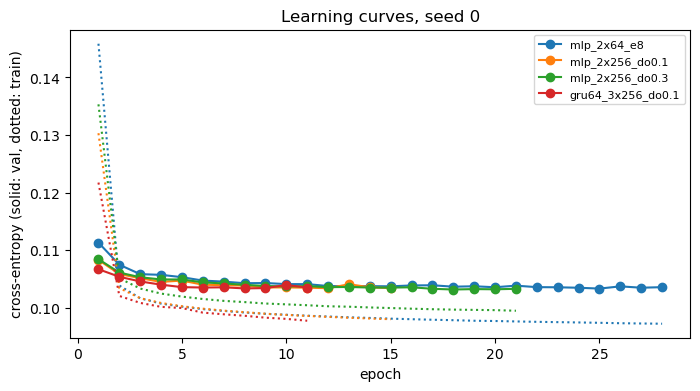

In [7]:
cur = pd.read_csv(T / "prob_curves.csv")
fig, ax = plt.subplots(figsize=(8, 4))
for n, c in zip(["mlp_2x64_e8", "mlp_2x256_do0.1", "mlp_2x256_do0.3",
                 "gru64_3x256_do0.1"], ["C0", "C1", "C2", "C3"]):
    g = cur[cur.run_id == f"p_{n}_seed0"]
    ax.plot(g.epoch, g.val_bce, "o-", color=c, label=n)
    ax.plot(g.epoch, g.train_bce, ":", color=c)
ax.set_xlabel("epoch")
ax.set_ylabel("cross-entropy (solid: val, dotted: train)")
ax.set_title("Learning curves, seed 0")
ax.legend(fontsize=8)
plt.show()

**Result.** <span style="color:#1f5fbf">[D10] Every non-linear model clears the bar by about the same amount: against calibrated persistence the chosen MLP 2×256, dropout 0.3 scores 0.154 ± 0.0002 (classic) and 0.117 ± 0.0006 (e-bike), and the other networks and LightGBM are within 0.0085 of it. Logistic regression on the same inputs only matches calibrated persistence (-0.000 / 0.002), so the gain needs a non-linear use of the inputs.</span>

<span style="color:#1f5fbf">[D11] The rule picked MLP 2×256, dropout 0.3. Its lead is small: +0.0010 / +0.0012 over dropout 0.1, +0.0031 / +0.0034 over LightGBM, and +0.0085 / +0.0034 over the base 2×64 (classic / e-bike; z = 2.1 / 2.0 once seed and station-sampling noise are both counted, `prob_noise.csv`).</span>
<span style="color:#c00000">[C2] The base's gap may come from early stopping rather than size: its seed that trained to epoch 25 reached 0.153 / 0.116, level with the larger nets, while the seeds that stopped at epochs 10 and 12 reached 0.142 and 0.142 (classic). Untested: a longer patience for the base.</span>

## 5. Where the model helps, and is it calibrated? (validation days)

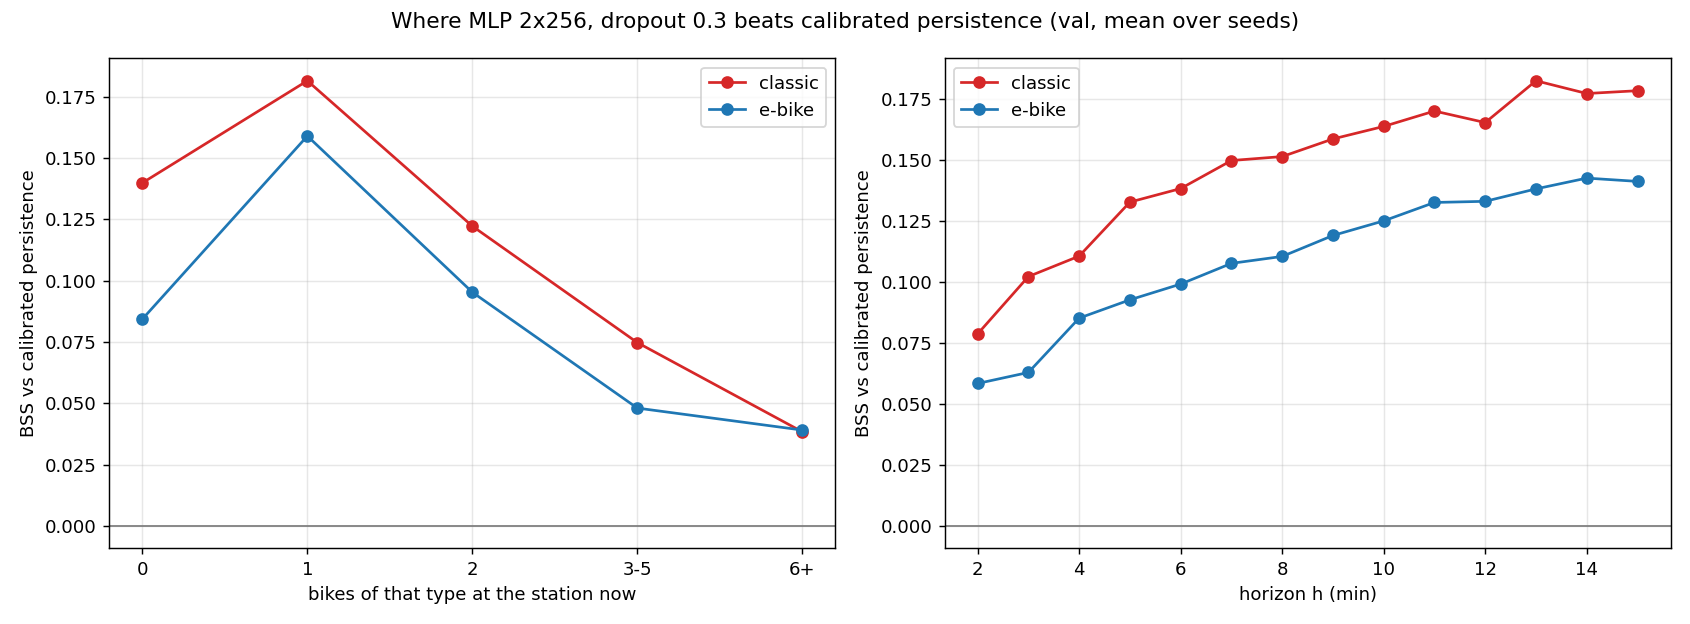

target  classic  ebike
group                 
0         0.140  0.084
1         0.182  0.159
2         0.122  0.095
3-5       0.075  0.048
6+        0.038  0.039


In [8]:
display(Image(filename=str(F / "prob_where.png"), width=900))
bc = pd.read_csv(T / "prob_by_count.csv")
print(bc[bc.model == ch["chosen"]].pivot(index="group", columns="target",
      values="bss_calpers").reindex(["0", "1", "2", "3-5", "6+"]).round(3))

<span style="color:#1f5fbf">[D12] The model helps most where a rider is most at risk, when one bike is left: BSS 0.182 (classic) and 0.159 (e-bike) against calibrated persistence, against 0.038 / 0.039 with 6 or more bikes. The gain also grows with the horizon, from 0.079 / 0.058 at h = 2 min to 0.177 / 0.143 at h = 14 min (hypothesis: the further ahead, the more the count now leaves open, and the more the other inputs can add).</span>

<span style="color:#1f5fbf">[D13] In rider terms: when one bike is there now, it is gone 7.6 % of the time (classic; 9.2 % for e-bikes) by t + h. A warning on the 10 % of these cases with the lowest forecast would catch 48 % of the times the bike is gone (41 % for e-bikes); the same warning from calibrated persistence catches 16 % (16 %).</span>

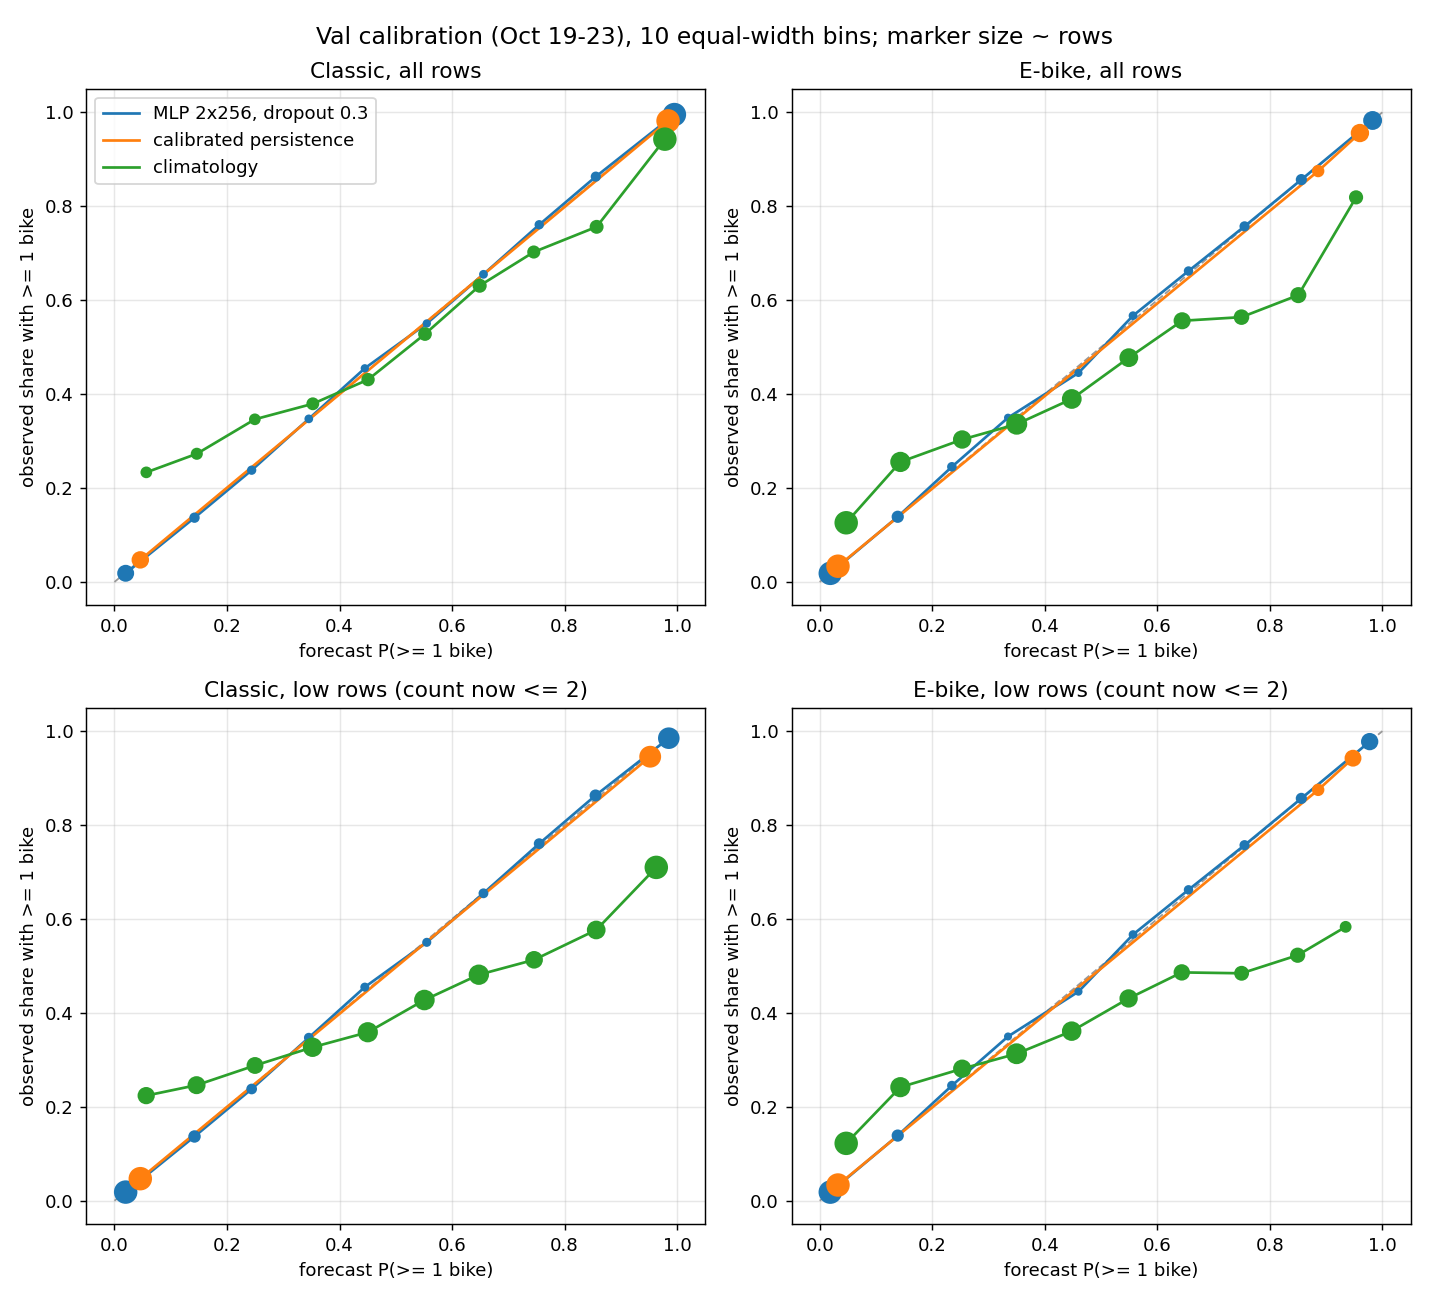

In [9]:
display(Image(filename=str(F / "prob_reliability.png"), width=800))

<span style="color:#1f5fbf">[D14] The forecasts are calibrated: in every bin with at least 1,000 rows the observed share is within 0.010 (classic) and 0.015 (e-bike) of the forecast. Climatology is not: it ignores the count now, so on these low-count rows it is off by up to 0.24.</span>

## 6. Test result (read once)

                 model  target  brier_mean  bss_pers_mean  bss_calpers_mean  bss_calpers_sd  bss_clim_mean
       mlp_2x256_do0.3 classic      0.0186         0.1721            0.1254          0.0006         0.8788
       mlp_2x256_do0.3   ebike      0.0320         0.1443            0.0924          0.0005         0.8534
           persistence classic      0.0225         0.0000           -0.0564             NaN         0.8536
calibrated persistence classic      0.0213         0.0534            0.0000             NaN         0.8614
           climatology classic      0.1534        -5.8296           -6.2148             NaN         0.0000
           persistence   ebike      0.0374         0.0000           -0.0607             NaN         0.8286
calibrated persistence   ebike      0.0352         0.0572            0.0000             NaN         0.8384
           climatology   ebike      0.2180        -4.8352           -5.1893             NaN         0.0000


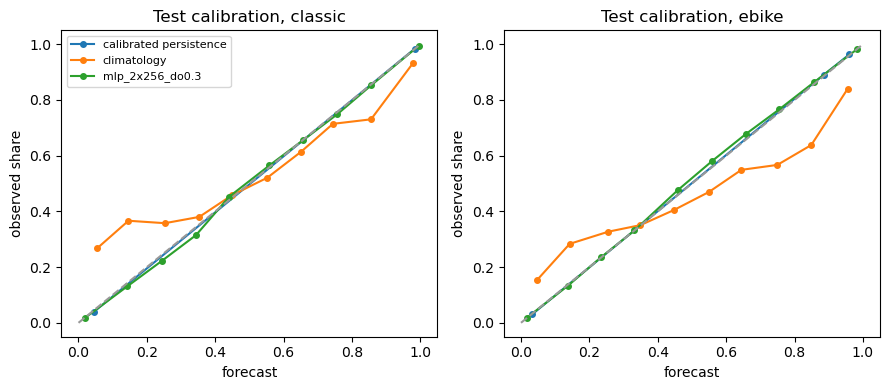

In [10]:
if (T / "prob_test_summary.csv").exists():
    t = pd.read_csv(T / "prob_test_summary.csv")
    t = t[t.subset == "all"]
    print(t[["model", "target", "brier_mean", "bss_pers_mean",
             "bss_calpers_mean", "bss_calpers_sd", "bss_clim_mean"]]
          .to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    tr = pd.read_csv(T / "prob_test_reliability.csv")
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    for ax, x in zip(axes, ["classic", "ebike"]):
        for m, g in tr[(tr.target == x) & (tr.rows >= 1000)].groupby("model"):
            ax.plot(g.p_mean, g.y_rate, "o-", ms=4, label=m)
        ax.plot([0, 1], [0, 1], "--", color="0.6")
        ax.set_title(f"Test calibration, {x}")
        ax.set_xlabel("forecast")
        ax.set_ylabel("observed share")
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

The test days (Oct 24–28) were read once, for the chosen model only, after the choice; the protocol was committed
before the read (`src/48_prob_test.py`). Nothing was tuned after it.

<span style="color:#1f5fbf">[D15] The gain holds on test but is smaller: 0.125 / 0.092 against calibrated persistence (val 0.154 / 0.117) and 0.172 / 0.144 against persistence. Calibration is a little looser than on validation: the largest bin gap is 0.029 / 0.022 (val 0.010 / 0.015).</span>
<span style="color:#c00000">[C3] Part of the drop is the weekend: the test week starts on a Saturday and the validation days have no weekend. On Sat Oct 24 and Sun Oct 25 the classic skill is 0.117 and 0.111, on Mon and Tue 0.140 and 0.127. Even the test weekdays are below validation, so the weekend is not the whole story (hypothesis: the weather or the season changed).</span>
<span style="color:#1f5fbf">[D16] Oct 28 holds only the early-morning hours (76,559 rows), where little changes. Dropping the 2,324 test rows at stations never seen in training changes the skill against calibrated persistence by at most 0.0002.</span>

## 7. Preliminary: data v2

<span style="color:#1f5fbf">[D17] A second, larger table (data v2, build 7f427d0c2919) adds the days to Nov 10 and a validation week with a weekend. So far only a 1-epoch smoke test has run, with the earlier count target (MSE), so its skill is the count skill against persistence, 1 − MSE_model / MSE_persistence, not the Brier skill above. It only shows that the pipeline runs end to end.</span>

In [11]:
v2 = pd.read_csv(T / "data_v2_smoke_fwd.csv")
v2 = v2[(v2.subset == "all") & (v2.day_type == "all")]
print("PRELIMINARY, count target (MSE), 1 epoch, val Oct 28 - Nov 3")
print(v2.pivot(index="model", columns="target", values="skill").round(3))

PRELIMINARY, count target (MSE), 1 epoch, val Oct 28 - Nov 3
target  classic  ebike
model                 
lstm      0.061  0.064
mlp       0.070  0.077


## 8. What is left, and is it feasible?

<span style="color:#1f5fbf">[D18] Done: data collection (running since Sep 29), the dataset, the score and its references, a small model search, and a test score taken once. Left, in order:</span>

1. <span style="color:#1f5fbf">[D19] Data v2 (Nov 16–19): retrain the chosen model on the larger table and check the weekend days.</span>
2. <span style="color:#1f5fbf">[D20] Longer history (Nov 19–22): give the GRU 60 min of past counts, which data v2 provides; freeze the final model on Nov 22.</span>
3. <span style="color:#1f5fbf">[D21] Rider-level evaluation (Nov 23–29): turn the probabilities into advice (e.g. 'go elsewhere' below a threshold) and count strandings avoided per 100 trips.</span>
4. <span style="color:#1f5fbf">[D22] Video (Dec 6) and final report (Dec 11).</span>

<span style="color:#1f5fbf">[D23] Each step reuses the scripts above. The 16 runs of this search took 3.8 h of run time in all, 0.9 h of wall time when run 6 at a time on one laptop CPU, so the plan fits the 5 h per person per week we have.</span>
<span style="color:#c00000">[C4] Dates of steps 1-3 are a proposal for the team.</span>